<a href="https://colab.research.google.com/github/Helomaylima/cn2026/blob/main/Atividade1910.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteração 0: x = [0. 0. 0.]
Iteração 1: x=0.600000, y=2.054545, z=-0.914545 | Erro=2.054545e+00
Iteração 2: x=0.988364, y=2.006711, z=-0.997002 | Erro=3.883636e-01
Iteração 3: x=1.000071, y=2.000279, z=-0.999986 | Erro=1.170777e-02
Iteração 4: x=1.000025, y=2.000004, z=-1.000005 | Erro=2.755404e-04
Iteração 5: x=1.000001, y=2.000000, z=-1.000000 | Erro=2.389216e-05
Iteração 6: x=1.000000, y=2.000000, z=-1.000000 | Erro=1.262607e-06

Convergência alcançada na iteração 6!


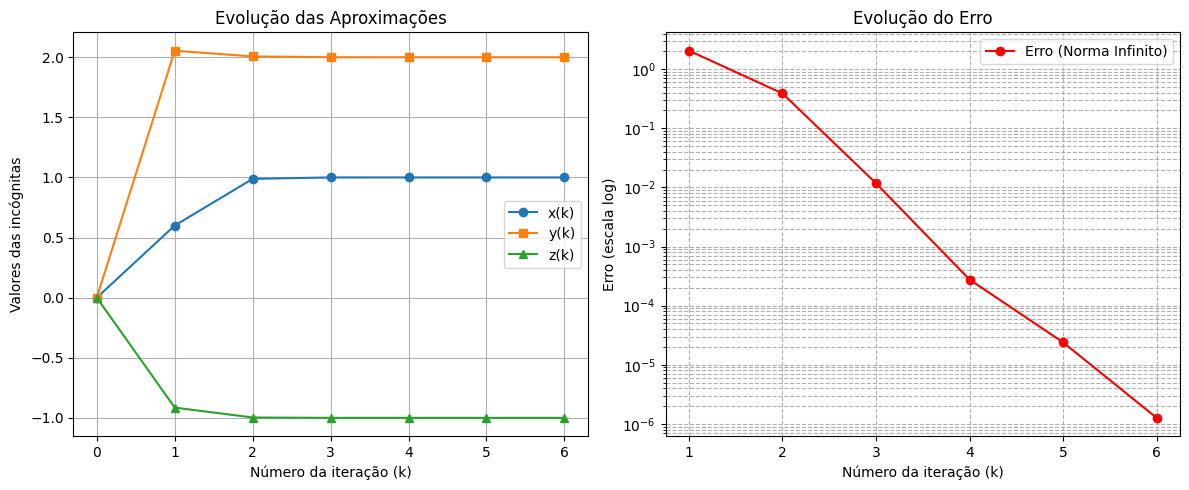

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Definindo a matriz A e o vetor b
A = np.array([[10.0, -1.0, 2.0],
              [-1.0, 11.0, -1.0],
              [2.0, -1.0, 10.0]])

b = np.array([6.0, 22.0, -10.0])

# Aproximação inicial x^(0) = [0, 0, 0]
x_ant = np.zeros(3)
tol = 1e-5
max_iter = 100

# Armazenar histórico para a tabela e gráficos
historico_x = [x_ant.copy()]
historico_erros = []

print(f"Iteração 0: x = {x_ant}")

for k in range(1, max_iter + 1):
    x_novo = np.zeros(3)

    # Fórmulas de Gauss-Seidel
    x_novo[0] = (b[0] - A[0, 1] * x_ant[1] - A[0, 2] * x_ant[2]) / A[0, 0]
    x_novo[1] = (b[1] - A[1, 0] * x_novo[0] - A[1, 2] * x_ant[2]) / A[1, 1]
    x_novo[2] = (b[2] - A[2, 0] * x_novo[0] - A[2, 1] * x_novo[1]) / A[2, 2]

    # Cálculo da norma do infinito (erro)
    erro = np.max(np.abs(x_novo - x_ant))

    historico_x.append(x_novo.copy())
    historico_erros.append(erro)

    print(f"Iteração {k}: x={x_novo[0]:.6f}, y={x_novo[1]:.6f}, z={x_novo[2]:.6f} | Erro={erro:.6e}")

    # Critério de parada
    if erro < tol:
        print(f"\nConvergência alcançada na iteração {k}!")
        break

    x_ant = x_novo.copy()

# Convertendo histórico para arrays numpy para facilitar os gráficos
historico_x = np.array(historico_x)

# --- Gráficos (Item 7) ---
plt.figure(figsize=(12, 5))

# Gráfico a) Evolução das aproximações x, y, z em função de k
plt.subplot(1, 2, 1)
k_valores = range(len(historico_x))
plt.plot(k_valores, historico_x[:, 0], 'o-', label='x(k)')
plt.plot(k_valores, historico_x[:, 1], 's-', label='y(k)')
plt.plot(k_valores, historico_x[:, 2], '^-', label='z(k)')
plt.xlabel('Número da iteração (k)')
plt.ylabel('Valores das incógnitas')
plt.title('Evolução das Aproximações')
plt.grid(True)
plt.legend()

# Gráfico b) Erro entre iterações em escala logarítmica
plt.subplot(1, 2, 2)
plt.plot(range(1, len(historico_erros) + 1), historico_erros, 'ro-', label='Erro (Norma Infinito)')
plt.yscale('log')
plt.xlabel('Número da iteração (k)')
plt.ylabel('Erro (escala log)')
plt.title('Evolução do Erro')
plt.grid(True, which="both", ls="--")
plt.legend()

plt.tight_layout()
plt.show()